# STUDY CASE DATA MINING  
## Prediksi Life Expectancy sampai tahap Streamlit

Notebook ini sudah disesuaikan dengan file **`Life_Expectancy_Data.csv`** dan dilanjutkan sampai pembuatan aplikasi **Streamlit** dengan tampilan yang lebih menarik.

## 1. Data Understanding

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from IPython.display import display
from pathlib import Path

sns.set_theme(style='whitegrid', palette='Blues')
plt.rcParams['figure.figsize'] = (10, 5)

DATA_PATH = Path('Life_Expectancy_Data.csv')
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip().str.replace(r'\s+', ' ', regex=True)

print(f'Shape dataset: {df.shape[0]} baris x {df.shape[1]} kolom')
display(df.head())

Shape dataset: 1649 baris x 22 kolom


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263,62,0.01,71.279624,65,1154,...,6,8.16,65,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271,64,0.01,73.523582,62,492,...,58,8.18,62,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268,66,0.01,73.219243,64,430,...,62,8.13,64,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272,69,0.01,78.184215,67,2787,...,67,8.52,67,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275,71,0.01,7.097109,68,3013,...,68,7.87,68,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [2]:
print('Daftar kolom:')
for col in df.columns:
    print('-', col)

print()
print('Cek tipe data:')
display(df.dtypes.to_frame('dtype'))

Daftar kolom:
- Country
- Year
- Status
- Life expectancy
- Adult Mortality
- infant deaths
- Alcohol
- percentage expenditure
- Hepatitis B
- Measles
- BMI
- under-five deaths
- Polio
- Total expenditure
- Diphtheria
- HIV/AIDS
- GDP
- Population
- thinness 1-19 years
- thinness 5-9 years
- Income composition of resources
- Schooling

Cek tipe data:


,dtype
Country,object
Year,int64
Status,object
Life expectancy,float64
Adult Mortality,int64
infant deaths,int64
Alcohol,float64
percentage expenditure,float64
Hepatitis B,int64
Measles,int64


In [3]:
summary_df = pd.DataFrame({
    'missing_values': df.isna().sum(),
    'duplicate_values': [df.duplicated().sum()] * len(df.columns),
    'zero_values': [(df[col] == 0).sum() if pd.api.types.is_numeric_dtype(df[col]) else np.nan for col in df.columns]
}, index=df.columns)

print('Ringkasan kualitas data:')
display(summary_df)

print(f"Jumlah baris duplikat: {df.duplicated().sum()}")
print(f"Jumlah total missing value: {int(df.isna().sum().sum())}")

Ringkasan kualitas data:


,missing_values,duplicate_values,zero_values
Country,0,0,NaN
Year,0,0,0.0
Status,0,0,NaN
Life expectancy,0,0,0.0
Adult Mortality,0,0,0.0
infant deaths,0,0,395.0
Alcohol,0,0,0.0
percentage expenditure,0,0,5.0
Hepatitis B,0,0,0.0
Measles,0,0,554.0


Jumlah baris duplikat: 0
Jumlah total missing value: 0


**Catatan:** pada dataset ini memang tidak ada nilai `null`, tetapi ada beberapa kolom numerik yang berisi nilai `0`. Untuk beberapa fitur seperti GDP, BMI, Population, dan Schooling, nilai `0` kurang realistis sehingga dapat diperlakukan sebagai *pseudo-missing values*.

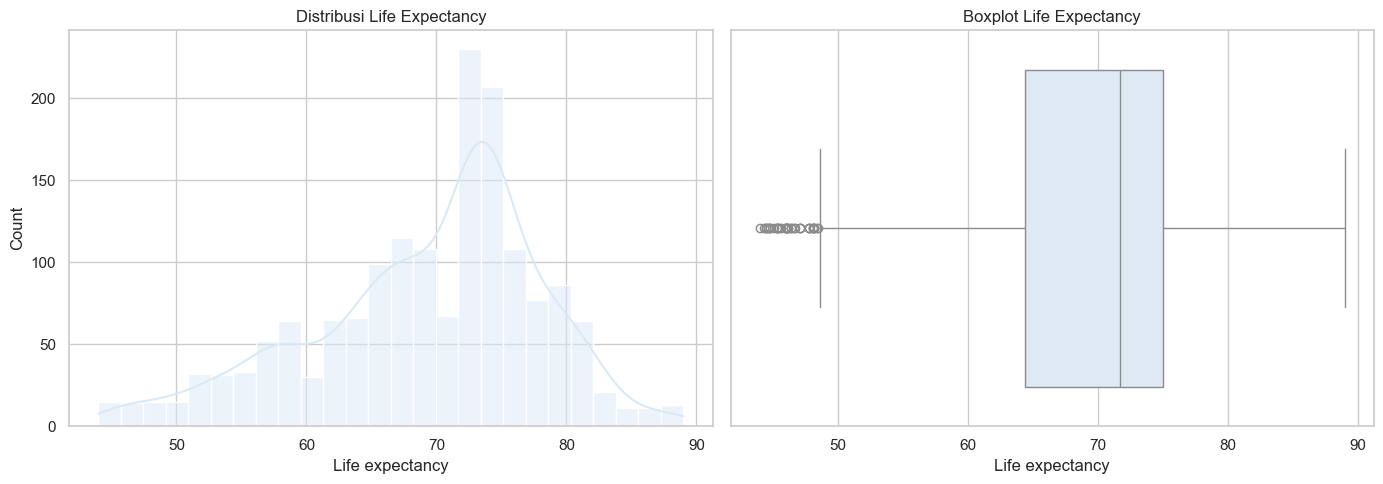

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['Life expectancy'], kde=True, ax=axes[0])
axes[0].set_title('Distribusi Life Expectancy')
axes[0].set_xlabel('Life expectancy')

sns.boxplot(x=df['Life expectancy'], ax=axes[1])
axes[1].set_title('Boxplot Life Expectancy')
axes[1].set_xlabel('Life expectancy')

plt.tight_layout()
plt.show()

Korelasi terhadap target Life expectancy:


,correlation
Life expectancy,1.000000
Schooling,0.727630
Income composition of resources,0.721083
BMI,0.542042
GDP,0.441322
percentage expenditure,0.409631
Alcohol,0.402718
Diphtheria,0.341331
Polio,0.327294
Hepatitis B,0.199935


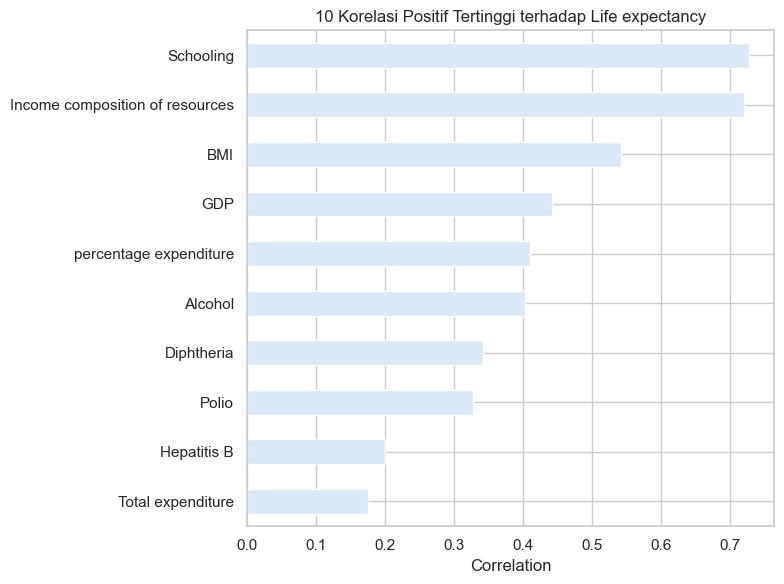

In [5]:
numeric_df = df.select_dtypes(include='number')
corr_target = numeric_df.corr(numeric_only=True)['Life expectancy'].sort_values(ascending=False)
print('Korelasi terhadap target Life expectancy:')
display(corr_target.to_frame('correlation'))

plt.figure(figsize=(8, 6))
plot_corr = corr_target.drop('Life expectancy').sort_values()
plot_corr.tail(10).plot(kind='barh')
plt.title('10 Korelasi Positif Tertinggi terhadap Life expectancy')
plt.xlabel('Correlation')
plt.tight_layout()
plt.show()

## 2. Data Pre-processing

In [6]:
df_clean = df.copy()

zero_as_missing_cols = [
    'Alcohol', 'Hepatitis B', 'BMI', 'Polio', 'Total expenditure',
    'Diphtheria', 'GDP', 'Population', 'thinness 1-19 years',
    'thinness 5-9 years', 'Income composition of resources', 'Schooling'
]

for col in zero_as_missing_cols:
    df_clean[col] = df_clean[col].replace(0, np.nan)

df_clean = df_clean.drop_duplicates().reset_index(drop=True)
df_clean['Status'] = df_clean['Status'].map({'Developing': 0, 'Developed': 1})

display(df_clean[zero_as_missing_cols].isna().sum().to_frame('missing_after_zero_handling'))
print(f'Shape setelah hapus duplikat: {df_clean.shape}')

,missing_after_zero_handling
Alcohol,0
Hepatitis B,0
BMI,0
Polio,0
Total expenditure,0
Diphtheria,0
GDP,0
Population,0
thinness 1-19 years,0
thinness 5-9 years,0


Shape setelah hapus duplikat: (1649, 22)


In [7]:
target_column = 'Life expectancy'
feature_df = df_clean.drop(columns=['Country', target_column]).copy()
target_series = df_clean[target_column].copy()

feature_defaults = feature_df.median(numeric_only=True).to_dict()
feature_ranges = {
    col: {
        'min': float(feature_df[col].min(skipna=True)),
        'max': float(feature_df[col].max(skipna=True))
    }
    for col in feature_df.columns
}

print('Jumlah fitur model:', feature_df.shape[1])
display(feature_df.head())

Jumlah fitur model: 20


,Year,Status,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,2015,0,263,62,0.01,71.279624,65,1154,19.1,83,6,8.16,65,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,2014,0,271,64,0.01,73.523582,62,492,18.6,86,58,8.18,62,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,2013,0,268,66,0.01,73.219243,64,430,18.1,89,62,8.13,64,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,2012,0,272,69,0.01,78.184215,67,2787,17.6,93,67,8.52,67,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,2011,0,275,71,0.01,7.097109,68,3013,17.2,97,68,7.87,68,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


## 3. Modeling

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(
    feature_df,
    target_series,
    test_size=0.2,
    random_state=42
)

models = {
    'Linear Regression': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', LinearRegression())
    ]),
    'Random Forest Regressor': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', RandomForestRegressor(
            n_estimators=400,
            random_state=42,
            n_jobs=-1
        ))
    ])
}

results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    predictions[name] = preds
    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, preds),
        'MSE': mean_squared_error(y_test, preds),
        'RMSE': mean_squared_error(y_test, preds) ** 0.5,
        'R2': r2_score(y_test, preds)
    })

evaluation_df = pd.DataFrame(results).sort_values(by='R2', ascending=False).reset_index(drop=True)
display(evaluation_df)

,Model,MAE,MSE,RMSE,R2
0,Random Forest Regressor,1.109714,3.460806,1.860324,0.951272
1,Linear Regression,2.383385,10.375845,3.221156,0.853908


In [9]:
best_model_name = evaluation_df.loc[0, 'Model']
best_model = models[best_model_name]
y_pred_best = predictions[best_model_name]

print(f'Model terbaik: {best_model_name}')
print(f'R2 terbaik: {evaluation_df.loc[0, "R2"]:.4f}')

Model terbaik: Random Forest Regressor
R2 terbaik: 0.9513


## 4. Evaluation & Insight

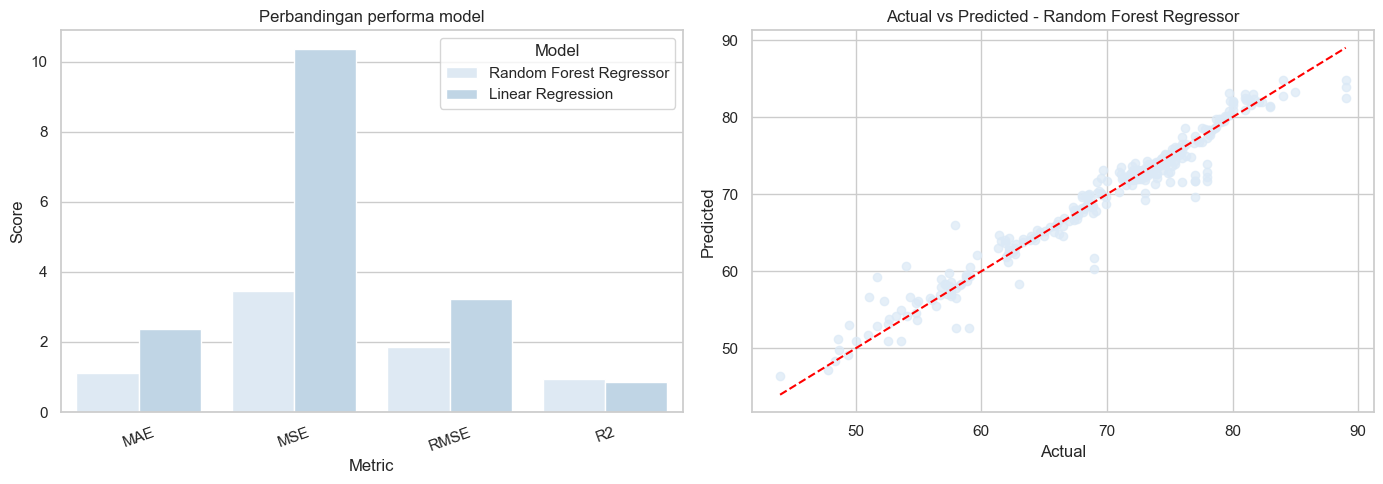

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=evaluation_df.melt(id_vars='Model', var_name='Metric', value_name='Score'),
            x='Metric', y='Score', hue='Model', ax=axes[0])
axes[0].set_title('Perbandingan performa model')
axes[0].tick_params(axis='x', rotation=20)

axes[1].scatter(y_test, y_pred_best, alpha=0.7)
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[1].set_title(f'Actual vs Predicted - {best_model_name}')
axes[1].set_xlabel('Actual')
axes[1].set_ylabel('Predicted')

plt.tight_layout()
plt.show()

,Feature,Importance
18,Income composition of resources,0.619996
13,HIV/AIDS,0.149411
2,Adult Mortality,0.146762
16,thinness 1-19 years,0.015452
17,thinness 5-9 years,0.009137
11,Total expenditure,0.008846
19,Schooling,0.008255
4,Alcohol,0.007771
0,Year,0.005458
8,BMI,0.004575


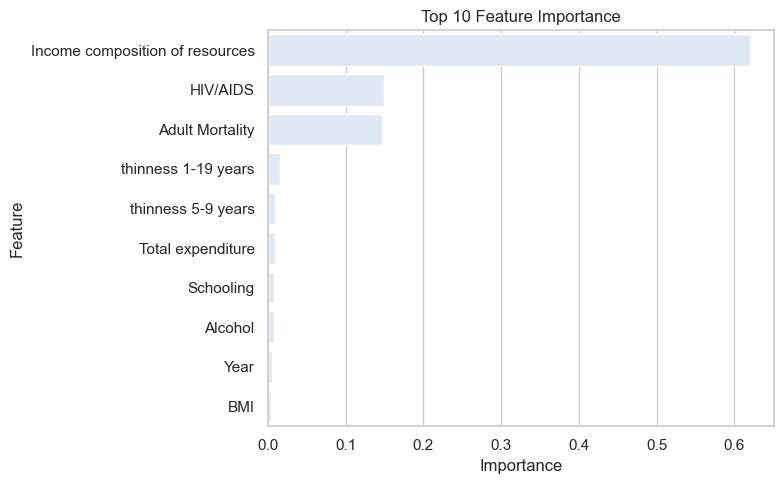

In [11]:
model_core = best_model.named_steps['model']

if hasattr(model_core, 'feature_importances_'):
    importance_df = pd.DataFrame({
        'Feature': feature_df.columns,
        'Importance': model_core.feature_importances_
    }).sort_values(by='Importance', ascending=False)

    display(importance_df.head(10))

    plt.figure(figsize=(8, 5))
    sns.barplot(data=importance_df.head(10), x='Importance', y='Feature')
    plt.title('Top 10 Feature Importance')
    plt.tight_layout()
    plt.show()
else:
    coef_df = pd.DataFrame({
        'Feature': feature_df.columns,
        'Coefficient': model_core.coef_
    }).sort_values(by='Coefficient', key=np.abs, ascending=False)
    display(coef_df.head(10))

In [12]:
print('Analisis singkat:')
print(f"- Model terbaik pada dataset ini adalah {best_model_name}.")
print(f"- Nilai R2 sebesar {evaluation_df.loc[0, 'R2']:.4f} menunjukkan model mampu menjelaskan variasi target dengan cukup baik.")
print('- Fitur seperti Adult Mortality, HIV/AIDS, Schooling, BMI, dan Income composition biasanya menjadi penjelas yang kuat terhadap harapan hidup.')

Analisis singkat:
- Model terbaik pada dataset ini adalah Random Forest Regressor.
- Nilai R2 sebesar 0.9513 menunjukkan model mampu menjelaskan variasi target dengan cukup baik.
- Fitur seperti Adult Mortality, HIV/AIDS, Schooling, BMI, dan Income composition biasanya menjadi penjelas yang kuat terhadap harapan hidup.


## 5. Save Model & Metadata

In [13]:
joblib.dump(best_model, 'best_model.pkl')
joblib.dump(list(feature_df.columns), 'feature_columns.pkl')
joblib.dump(feature_defaults, 'feature_defaults.pkl')
joblib.dump(feature_ranges, 'feature_ranges.pkl')
joblib.dump(best_model_name, 'model_name.pkl')

print('Semua file model berhasil disimpan.')

Semua file model berhasil disimpan.


## 6. Build Streamlit App

In [14]:
app_code = r'''import streamlit as st
import pandas as pd
import numpy as np
import joblib

st.set_page_config(
    page_title="Life Expectancy Dashboard",
    page_icon="🌍",
    layout="wide",
    initial_sidebar_state="expanded"
)

model = joblib.load("best_model.pkl")
feature_columns = joblib.load("feature_columns.pkl")
defaults = joblib.load("feature_defaults.pkl")
feature_ranges = joblib.load("feature_ranges.pkl")
model_name = joblib.load("model_name.pkl")

friendly_labels = {
    "Year": "Year",
    "Status": "Status",
    "Adult Mortality": "Adult Mortality",
    "infant deaths": "Infant deaths",
    "Alcohol": "Alcohol consumption",
    "percentage expenditure": "Percentage expenditure",
    "Hepatitis B": "Hepatitis B immunization",
    "Measles": "Measles cases",
    "BMI": "BMI",
    "under-five deaths": "Under-five deaths",
    "Polio": "Polio immunization",
    "Total expenditure": "Total health expenditure",
    "Diphtheria": "Diphtheria immunization",
    "HIV/AIDS": "HIV/AIDS",
    "GDP": "GDP",
    "Population": "Population",
    "thinness 1-19 years": "Thinness 1-19 years",
    "thinness 5-9 years": "Thinness 5-9 years",
    "Income composition of resources": "Income composition",
    "Schooling": "Schooling"
}

sections = {
    "Profil negara": ["Year", "Status", "Population", "GDP", "Schooling", "Income composition of resources"],
    "Kesehatan & imunisasi": ["Adult Mortality", "Alcohol", "Hepatitis B", "Polio", "Diphtheria", "Total expenditure"],
    "Penyakit & nutrisi": ["infant deaths", "under-five deaths", "Measles", "BMI", "HIV/AIDS", "thinness 1-19 years", "thinness 5-9 years", "percentage expenditure"]
}

st.markdown(
    """
    <style>
    .stApp {
        background: linear-gradient(180deg, #f7fbff 0%, #eef6ff 100%);
    }
    .hero {
        padding: 1.35rem 1.5rem;
        border-radius: 20px;
        background: linear-gradient(135deg, #0f172a 0%, #1d4ed8 55%, #38bdf8 100%);
        color: white;
        box-shadow: 0 14px 32px rgba(37, 99, 235, 0.22);
        margin-bottom: 1rem;
    }
    .hero h1 {
        margin: 0;
        font-size: 2.2rem;
    }
    .hero p {
        margin: 0.45rem 0 0 0;
        font-size: 1rem;
        opacity: 0.95;
    }
    .mini-card {
        background: white;
        border-radius: 18px;
        padding: 1rem 1.1rem;
        box-shadow: 0 10px 24px rgba(15, 23, 42, 0.08);
        border: 1px solid rgba(148, 163, 184, 0.18);
    }
    div[data-testid="stMetric"] {
        background: white;
        border: 1px solid rgba(148, 163, 184, 0.2);
        padding: 16px;
        border-radius: 18px;
        box-shadow: 0 8px 20px rgba(15, 23, 42, 0.06);
    }
    </style>
    """,
    unsafe_allow_html=True,
)

st.markdown(
    f"""
    <div class="hero">
        <h1>🌍 Life Expectancy Dashboard</h1>
        <p>Prediksi harapan hidup berdasarkan indikator kesehatan, ekonomi, dan nutrisi. Model aktif: <b>{model_name}</b>.</p>
    </div>
    """,
    unsafe_allow_html=True,
)


def safe_bounds(col):
    info = feature_ranges.get(col, {})
    mn = float(info.get("min", 0.0))
    mx = float(info.get("max", max(1.0, defaults.get(col, 1.0) * 2)))
    if not np.isfinite(mn) or not np.isfinite(mx) or mn == mx:
        mn, mx = 0.0, max(1.0, defaults.get(col, 1.0) * 2)
    return mn, mx


def render_input(col):
    label = friendly_labels.get(col, col)
    default_val = float(defaults.get(col, 0.0))
    mn, mx = safe_bounds(col)

    if col == "Status":
        return st.selectbox(
            label,
            options=[0, 1],
            index=1 if default_val >= 0.5 else 0,
            format_func=lambda x: "Developed" if x == 1 else "Developing"
        )

    if 0 <= mn and mx <= 100:
        return st.slider(label, min_value=float(mn), max_value=float(mx), value=float(np.clip(default_val, mn, mx)))

    step = max((mx - mn) / 200, 0.1)
    return st.number_input(
        label,
        min_value=float(mn),
        max_value=float(mx),
        value=float(np.clip(default_val, mn, mx)),
        step=float(step),
        format="%.4f"
    )

with st.sidebar:
    st.header("⚙️ Input fitur")
    st.caption("Ubah indikator negara lalu lihat perubahan prediksi secara real-time.")
    user_input = {}
    for section, cols in sections.items():
        with st.expander(section, expanded=(section == "Profil negara")):
            for col in cols:
                user_input[col] = render_input(col)

for col in feature_columns:
    if col not in user_input:
        user_input[col] = float(defaults.get(col, 0.0))

input_df = pd.DataFrame([user_input])[feature_columns]
prediction = float(model.predict(input_df)[0])
progress_value = max(0.0, min(prediction / 90.0, 1.0))

if prediction < 60:
    category = "Perlu perhatian"
    category_note = "Harapan hidup relatif rendah dibanding rata-rata global."
elif prediction < 75:
    category = "Menengah"
    category_note = "Harapan hidup berada di level menengah dan masih dapat ditingkatkan."
else:
    category = "Tinggi"
    category_note = "Harapan hidup termasuk tinggi dan menunjukkan profil kesehatan yang baik."

c1, c2, c3 = st.columns(3)
with c1:
    st.metric("Prediksi Life Expectancy", f"{prediction:.2f} tahun")
with c2:
    st.metric("Kategori", category)
with c3:
    status_label = "Developed" if input_df["Status"].iloc[0] == 1 else "Developing"
    st.metric("Status negara", status_label)

st.progress(progress_value, text=f"Posisi prediksi pada skala 0-90 tahun: {prediction:.2f}")

left, right = st.columns([1.2, 1])
with left:
    st.markdown('<div class="mini-card">', unsafe_allow_html=True)
    st.subheader("Ringkasan interpretasi")
    st.write(category_note)

    notes = []
    if input_df["Adult Mortality"].iloc[0] > defaults["Adult Mortality"]:
        notes.append("Adult Mortality di atas median dataset cenderung menekan life expectancy.")
    if input_df["Schooling"].iloc[0] > defaults["Schooling"]:
        notes.append("Schooling di atas median biasanya mendorong prediksi life expectancy lebih tinggi.")
    if input_df["Income composition of resources"].iloc[0] > defaults["Income composition of resources"]:
        notes.append("Income composition yang lebih baik berkorelasi positif dengan harapan hidup.")
    if input_df["HIV/AIDS"].iloc[0] > defaults["HIV/AIDS"]:
        notes.append("Nilai HIV/AIDS yang tinggi sering dikaitkan dengan penurunan harapan hidup.")
    if input_df["BMI"].iloc[0] < defaults["BMI"]:
        notes.append("BMI di bawah median dapat menjadi sinyal masalah gizi atau kesehatan populasi.")
    if not notes:
        notes.append("Kombinasi input saat ini cukup dekat dengan nilai tengah dataset.")

    for note in notes:
        st.write(f"- {note}")
    st.markdown('</div>', unsafe_allow_html=True)

with right:
    chart_features = [
        "Adult Mortality", "Schooling", "Income composition of resources",
        "BMI", "HIV/AIDS", "GDP"
    ]
    normalized = {}
    for col in chart_features:
        mn, mx = safe_bounds(col)
        normalized[friendly_labels[col]] = (float(input_df[col].iloc[0]) - mn) / (mx - mn + 1e-9)
    chart_df = pd.DataFrame({"Normalized value": normalized}).T
    st.subheader("Profil input (normalisasi 0-1)")
    st.bar_chart(chart_df)

tab1, tab2 = st.tabs(["📋 Detail Input", "ℹ️ Tentang Model"])
with tab1:
    show_df = input_df.rename(columns=friendly_labels).T
    show_df.columns = ["Nilai"]
    st.dataframe(show_df, use_container_width=True)

with tab2:
    st.write(f"Model terbaik yang disimpan: **{model_name}**")
    st.write("Fitur yang digunakan:")
    st.write(", ".join([friendly_labels.get(col, col) for col in feature_columns]))
    st.info("Aplikasi ini cocok untuk demo akademik atau portofolio data mining. Untuk produksi, tambahkan validasi input, logging, dan monitoring model.")
'''
with open('app.py', 'w', encoding='utf-8') as f:
    f.write(app_code)

print('File app.py berhasil dibuat.')

File app.py berhasil dibuat.


In [15]:
requirements_code = '''pandas
numpy
matplotlib
seaborn
scikit-learn
joblib
streamlit
'''
with open('requirements.txt', 'w', encoding='utf-8') as f:
    f.write(requirements_code)

print('File requirements.txt berhasil dibuat.')

File requirements.txt berhasil dibuat.


### Cara menjalankan Streamlit
Jalankan perintah berikut di terminal / command prompt pada folder yang sama:

```bash
pip install -r requirements.txt
streamlit run app.py
```


In [16]:
from pathlib import Path

for file_name in ['best_model.pkl', 'feature_columns.pkl', 'feature_defaults.pkl', 'feature_ranges.pkl', 'model_name.pkl', 'app.py', 'requirements.txt']:
    print(file_name, '->', Path(file_name).resolve())

best_model.pkl -> /Users/prisaayudianingtiyas/Downloads/best_model.pkl
feature_columns.pkl -> /Users/prisaayudianingtiyas/Downloads/feature_columns.pkl
feature_defaults.pkl -> /Users/prisaayudianingtiyas/Downloads/feature_defaults.pkl
feature_ranges.pkl -> /Users/prisaayudianingtiyas/Downloads/feature_ranges.pkl
model_name.pkl -> /Users/prisaayudianingtiyas/Downloads/model_name.pkl
app.py -> /Users/prisaayudianingtiyas/Downloads/app.py
requirements.txt -> /Users/prisaayudianingtiyas/Downloads/requirements.txt
